# S18 · RL sin modelo: Gymnasium y Q-Learning

En la S17 resolvimos FrozenLake **conociendo** $P(s'|s,a)$ y $R(s,a)$. Hoy el agente no los conoce: solo puede jugar.

1. Gymnasium: el contrato `reset` / `step`
2. Agente aleatorio (la línea base)
3. De Bellman a Q-Learning: cambiar la esperanza por muestras
4. Q-Learning tabular en FrozenLake y comparación con $Q^\star$ de la S17
5. El bug de `terminated`
6. SARSA: un símbolo de diferencia
7. Efecto de $\alpha$ y $\gamma$
8. Un entorno de trading mínimo y cómo validarlo
9. Por qué la tabla no escala a trading

In [1]:
import sys; sys.path.append("src")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import gymnasium as gym
from frozenlake_utils import *

SEED = 42
np.set_printoptions(precision=3, suppress=True)

## 1. Gymnasium: el contrato estándar

Todo entorno expone lo mismo, sin importar si es un juego o un mercado:

| método | devuelve |
|---|---|
| `env.reset(seed)` | `obs, info` |
| `env.step(a)` | `obs, reward, terminated, truncated, info` |

- `terminated`: terminó por la **tarea** (hoyo, meta, quiebra). El futuro vale 0: **no** se hace bootstrap.
- `truncated`: terminó por **tiempo** (límite de pasos, fin de datos). El futuro existe: **sí** se hace bootstrap.

In [2]:
env = gym.make("FrozenLake-v1", is_slippery=True)
nS, nA = env.observation_space.n, env.action_space.n

print("observation_space:", env.observation_space, "  action_space:", env.action_space)
print("límite de pasos por episodio:", env.spec.max_episode_steps)

obs, info = env.reset(seed=SEED)
print("\nobs inicial:", obs, " info:", info)

a = 2                                                   # Derecha
obs, r, terminated, truncated, info = env.step(a)
print(f"step({a}) -> obs={obs}, r={r}, terminated={terminated}, truncated={truncated}, info={info}")

observation_space: Discrete(16)   action_space: Discrete(4)
límite de pasos por episodio: 100

obs inicial: 0  info: {'prob': 1}
step(2) -> obs=1, r=0, terminated=False, truncated=False, info={'prob': 0.3333333333333333}


**Observa:** pedimos Derecha y no necesariamente acabamos en la celda 1: el hielo resbala.
`info["prob"]` es la probabilidad de esa transición; el agente **no** debe usarla (sería espiar el modelo).

**Interpretación**: Se empieza en la casilla 0 y la accion 2 es derecha. Llega a casilla 1, pero info dice que eso tenia probabilidad de 1/3 porque el "hielo" tambien lo puede resbalar hacia arriba o abajo. Además, cada episodio se corta a los 100 pasos y esto es lo que se marca como truncado.

## 2. Agente aleatorio: la línea base

Antes de entrenar nada, medimos qué tan bien le va a quien elige al azar (`action_space.sample()`).
Contamos también **cómo** termina cada episodio.

In [3]:
def correr_aleatorio(env, n_episodios=2000, semilla=SEED):
    # Agente aleatorio: devuelve recompensas por episodio y cuántos terminaron vs. truncaron.
    env.action_space.seed(semilla)
    env.reset(seed=semilla)
    retornos, fin = [], {"terminated": 0, "truncated": 0}
    for _ in range(n_episodios):
        obs, _ = env.reset()
        total, terminado, truncado = 0.0, False, False
        while not (terminado or truncado):
            obs, r, terminado, truncado, _ = env.step(env.action_space.sample())
            total += r
        fin["terminated" if terminado else "truncated"] += 1
        retornos.append(total)
    return np.array(retornos), fin

ret_azar, fin = correr_aleatorio(env)
print(f"FrozenLake · aleatorio: éxito {ret_azar.mean():.1%}   fines: {fin}")

env_cp = gym.make("CartPole-v1")
ret_cp, fin_cp = correr_aleatorio(env_cp, n_episodios=500)
print(f"CartPole   · aleatorio: retorno medio {ret_cp.mean():.1f} (min {ret_cp.min():.0f}, max {ret_cp.max():.0f}) de 500 posibles   fines: {fin_cp}")

FrozenLake · aleatorio: éxito 1.8%   fines: {'terminated': 2000, 'truncated': 0}
CartPole   · aleatorio: retorno medio 21.6 (min 8, max 73) de 500 posibles   fines: {'terminated': 500, 'truncated': 0}


El mismo código corre en dos entornos distintos: esa es la ventaja de un contrato estándar.
En CartPole todo termina por `terminated` (el palo cae); en FrozenLake casi todo es caer en un hoyo.

**intepretacion**: Jugando al azar el agente llega a la meta solo el 1.8% de las veces, y todos los episodios terminan casi siempre por "terninated" por carer en un hoyo antes de los 100 pasos. Con CartPole aguanta 21.6 pasos de 500 posibles. El 1.8% es la base que se debe superar.

## 3. De Bellman a Q-Learning

Value iteration (S17) necesitaba el modelo:

$$Q(s,a) \leftarrow \underbrace{\sum_{s'}P(s'|s,a)}_{\text{desconocido}}\Big[r + \gamma\max_{a'}Q(s',a')\Big]$$

**Idea:** no podemos calcular la esperanza, pero sí **observar** una transición $(s,a,r,s')$ y movernos un poco hacia ella.
Eso es Q-Learning (Watkins y Dayan, 1992):

$$Q(s,a) \leftarrow Q(s,a) + \alpha\Big[\underbrace{r + \gamma\max_{a'}Q(s',a')}_{\text{TD target}} - Q(s,a)\Big]$$

El corchete es el **error TD** $\delta$. Para explorar usamos $\varepsilon$-greedy: con prob. $\varepsilon$ una acción al azar, si no $\arg\max_a Q(s,a)$.

In [4]:
def q_learning(env, episodios=20_000, alpha=0.1, gamma=0.99,
               eps=1.0, eps_min=0.05, decay=0.9997, metodo="q",
               bug_terminal=False, Q0=0.0, semilla=SEED):
    # Q-Learning (Watkins y Dayan, 1992) y SARSA (Rummery y Niranjan, 1994) tabulares.
    #   Q-Learning: target = r + γ·max_a' Q(s',a')
    #   SARSA:      target = r + γ·Q(s',a'),  a' = la acción que realmente se tomará
    #   Si terminated: target = r   (bug_terminal=True ignora esta regla, a propósito)
    rng = np.random.default_rng(semilla)
    Q = np.full((nS, nA), Q0, dtype=float)
    elegir = lambda s: int(rng.integers(nA)) if rng.random() < eps else int(Q[s].argmax())
    retornos = []
    env.reset(seed=semilla)
    for ep in range(episodios):
        s, _ = env.reset()
        a = elegir(s)
        terminado = truncado = False
        while not (terminado or truncado):
            s2, r, terminado, truncado, _ = env.step(a)
            a2 = elegir(s2)
            futuro = Q[s2].max() if metodo == "q" else Q[s2, a2]
            if terminado and not bug_terminal:
                futuro = 0.0                                # sin bootstrap al terminar
            Q[s, a] += alpha * (r + gamma * futuro - Q[s, a])
            s, a = s2, a2
        retornos.append(r)                                  # en FrozenLake el retorno es la última r
        eps = max(eps_min, eps * decay)
    return Q, np.array(retornos)

**Intepretación**: A diferencia del value iteration, aqui no se conocen las probabilidades de "resbalarse". Después de cada jugada se ajusta un poco hacia lo que acaba de observar, y alpha controla el ajuste.

## 4. Q-Learning en FrozenLake

Entrenamos y, como referencia, calculamos $Q^\star$ con value iteration (lo de la S17). El agente **nunca** ve `P` ni `R`.

In [5]:
gamma = 0.99
P, R = construir_modelo(env)                    # solo para comparar, el agente no lo usa
V = np.zeros(nS)
for _ in range(1500):
    Q_star = R + gamma * np.einsum("sap,p->sa", P, V)
    V = Q_star.max(axis=1)
pi_star = Q_star.argmax(axis=1)

Q_ql, ret_ql = q_learning(env, gamma=gamma)
pi_ql = Q_ql.argmax(axis=1)

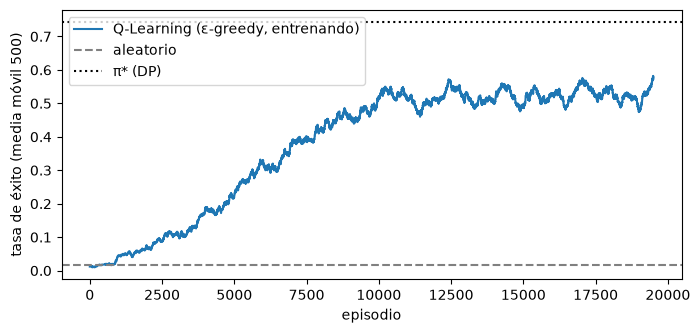

In [6]:
w = 500
media = lambda x: np.convolve(x, np.ones(w) / w, mode="valid")
plt.figure(figsize=(8, 3.5))
plt.plot(media(ret_ql), label="Q-Learning (ε-greedy, entrenando)")
plt.axhline(ret_azar.mean(), color="gray", ls="--", label="aleatorio")
plt.axhline(simular_politica(env, pi_star, semilla=SEED), color="k", ls=":", label="π* (DP)")
plt.xlabel("episodio"); plt.ylabel(f"tasa de éxito (media móvil {w})"); plt.legend(); plt.show()

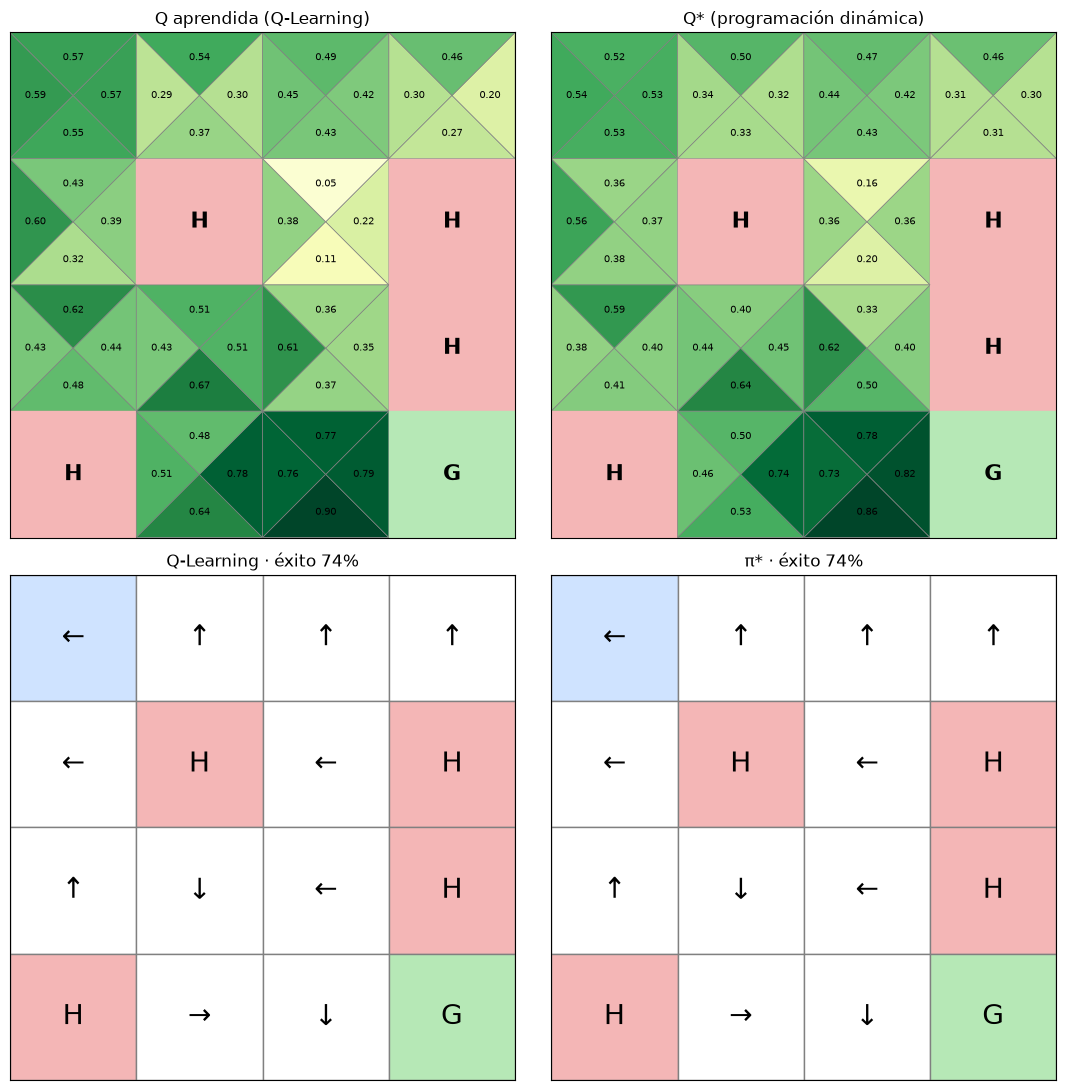

In [7]:
vmax = Q_star[[s for s in range(nS) if s not in estados_terminales(env)]].max()
fig, ax = plt.subplots(2, 2, figsize=(11, 11))
graficar_Q(Q_ql, env, "Q aprendida (Q-Learning)", ax[0, 0], vmax)
graficar_Q(Q_star, env, "Q* (programación dinámica)", ax[0, 1], vmax)
graficar_politica(pi_ql, env, f"Q-Learning · éxito {simular_politica(env, pi_ql, semilla=SEED):.0%}", ax[1, 0])
graficar_politica(pi_star, env, f"π* · éxito {simular_politica(env, pi_star, semilla=SEED):.0%}", ax[1, 1])
plt.tight_layout(); plt.show()

**Lectura:**
- La curva de entrenamiento queda **debajo** de la política final: mientras entrena, el agente sigue explorando con $\varepsilon$.
- Las diferencias con $Q^\star$ están en celdas poco visitadas. Q-Learning converge a $Q^\star$ solo si visita cada $(s,a)$ infinitas veces.
- Q-Learning es **off-policy**: se comporta con $\varepsilon$-greedy pero aprende el valor de la política greedy (el `max`).

**interpretación:** El agente aprender la política de pi* y se tiene un 74% de exito. La curva de entrenamiento se queda en 0.5 a 0.55 porque el agente sigue explorado al azar un 5% del tiempo. Los valores de Q sí difieren un poco de Q* pero eso no cambia que acción es la mejor.

## 5. El bug de `terminated`

Si olvidamos quitar el bootstrap al terminar, el valor de los hoyos y la meta se "filtra" hacia atrás.
Con $Q_0=0$ no se nota (las celdas terminales nunca se actualizan y quedan en 0). Con $Q_0=1$ (inicialización optimista) aparece:

In [8]:
Q_ok,  _ = q_learning(env, Q0=1.0)
Q_bug, _ = q_learning(env, Q0=1.0, bug_terminal=True)
no_term = [s for s in range(nS) if s not in estados_terminales(env)]

# El retorno máximo posible en FrozenLake es 1: ningún Q debería pasar de 1
print(f"{'':10s}  max Q(s,a)   Q(6,←)   éxito greedy")
print(f"{'Q*':10s}  {Q_star[no_term].max():10.3f}   {Q_star[6, 0]:6.3f}")
for nombre, Q in [("correcto", Q_ok), ("con bug", Q_bug)]:
    print(f"{nombre:10s}  {Q[no_term].max():10.3f}   {Q[6, 0]:6.3f}   {simular_politica(env, Q.argmax(1), semilla=SEED):11.0%}")

            max Q(s,a)   Q(6,←)   éxito greedy
Q*               0.863    0.358
correcto         0.865    0.120           75%
con bug          1.768    1.084           75%


En la celda 6, ← cae al hoyo 5 con prob. 1/3. Con el bug, el agente toma $Q(\text{hoyo})=1$ como futuro: cree que caer vale $\gamma\cdot 1$ y aparecen valores **mayores a 1**, imposibles.
Aquí la política greedy sale parecida porque el error infla casi todo por igual, pero los valores están corruptos y en otro problema sí cambian el orden de las acciones. Es un bug silencioso: el código corre y "aprende".
En trading, marcar el último bar del histórico como `terminated` enseña que "el mundo se acaba" ahí. El fin de datos es `truncated`.

**Interpretación:** Con el bug aparecen los valorees 1.768 y 1.084 que son imposibles porque lo maximo que se puede ganar es 1. Lo correcto sería 0.865, casi igual que Q*. Lo interesante de esto es que ambas poíticas tienen la misma probabilidad de éxito, asi que solo viendo los resultados podríamos darnos cuenta de que los valores están mal.

## 6. SARSA: on-policy

$$Q(s,a) \leftarrow Q(s,a) + \alpha\big[r + \gamma\,Q(s',\mathbf{a'}) - Q(s,a)\big]$$

Un solo cambio: $\max_{a'}Q(s',a')$ se reemplaza por $Q(s',a')$ de la acción que **realmente** se toma (incluida la exploración).
SARSA aprende el valor de la política $\varepsilon$-greedy, así que descuenta el costo de sus propios errores: es más cauteloso.

In [9]:
# ε fijo en 0.1 para que la diferencia se vea: ambos exploran igual todo el tiempo
Q_q, r_q = q_learning(env, eps=0.1, eps_min=0.1, metodo="q")
Q_s, r_s = q_learning(env, eps=0.1, eps_min=0.1, metodo="sarsa")

print(f"{'':12s}  éxito entrenando (ε=0.1)   éxito greedy final   V(0) estimado")
for nombre, Q, r in [("Q-Learning", Q_q, r_q), ("SARSA", Q_s, r_s)]:
    print(f"{nombre:12s}  {r[-5000:].mean():22.1%}   {simular_politica(env, Q.argmax(1), semilla=SEED):18.1%}   {Q[0].max():.3f}")
print(f"{'V*(0) de DP':12s}  {'':22s}   {'':18s}   {Q_star[0].max():.3f}")

              éxito entrenando (ε=0.1)   éxito greedy final   V(0) estimado
Q-Learning                     39.6%                74.2%   0.558
SARSA                          37.1%                63.5%   0.277
V*(0) de DP                                                 0.542


SARSA estima un $V(0)$ menor: incluye el riesgo de que, 10% de las veces, haga algo al azar.
**Regla práctica:** si exploras en simulador y solo despliegas la política final, Q-Learning. Si aprendes operando dinero real, la cautela de SARSA vale P&L.

**Interpretación**: SARSA estima la salida en 0.277, mucho menos que Q-learning que está en 0.558 yque el valor real de 0.542 porque toma en cuenta sus propias jugadas al azar. La politica final tambien es peor (63.5 vs 74.2%)

## 7. Efecto de $\alpha$ y $\gamma$

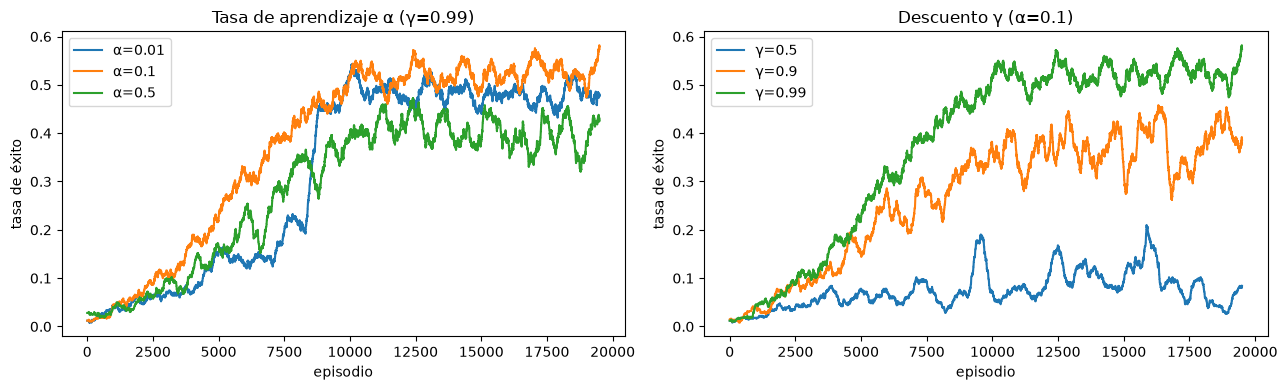

In [10]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
for alpha in [0.01, 0.1, 0.5]:
    _, r = q_learning(env, alpha=alpha)
    ax[0].plot(media(r), label=f"α={alpha}")
ax[0].set_title("Tasa de aprendizaje α (γ=0.99)")

for g in [0.5, 0.9, 0.99]:
    _, r = q_learning(env, gamma=g)
    ax[1].plot(media(r), label=f"γ={g}")
ax[1].set_title("Descuento γ (α=0.1)")
for a_ in ax:
    a_.set_xlabel("episodio"); a_.set_ylabel("tasa de éxito"); a_.legend()
plt.tight_layout(); plt.show()

- $\alpha$ chico: estable pero lento. $\alpha$ grande: rápido pero ruidoso (el hielo hace que una sola muestra engañe mucho).
- $\gamma$ chico: el agente es miope y no "ve" la meta desde lejos (igual que en la S17).

**Intepretación:** Con alpha=0.1 se obtiene la mejor curva. Con 0.01 aprender muy lento al principio y con 0.5 se queda más abajo y más ruidoso, porque cada resbalón mueve demasiado la tabla.

## 8. Un entorno de trading propio

Heredamos de `gym.Env` y cumplimos el contrato. Usamos precios sintéticos (semilla 42) para no depender de descargas.

- Acciones: `0` corto, `1` fuera, `2` largo  →  posición $\in\{-1,0,+1\}$
- Observación: los últimos `window` rendimientos (hasta $t-1$) y la posición actual
- Recompensa: $\text{pnl}_t = \text{pos}_t\,(p_{t+1}-p_t) - c\,|\Delta\text{pos}|\,p_t$, escalada por el capital inicial
- `terminated` = ruina (equity < 50%); `truncated` = se acabaron los datos

In [11]:
from gymnasium import spaces

class TradingEnv(gym.Env):
    def __init__(self, df, window=30, cost=0.001, init_cash=100_000):
        super().__init__()
        self.df, self.window, self.cost, self.init_cash = df, window, cost, init_cash
        self.action_space = spaces.Discrete(3)                       # 0 corto, 1 fuera, 2 largo
        self.observation_space = spaces.Box(-np.inf, np.inf, shape=(window + 1,), dtype=np.float32)

    def _obs(self):
        rets = self.df["ret"].iloc[self.t - self.window : self.t].values   # solo hasta t-1
        return np.append(rets, self.position).astype(np.float32)

    def reset(self, seed=None, options=None):
        super().reset(seed=seed)
        self.t, self.position, self.equity = self.window, 0, self.init_cash
        return self._obs(), {}

    def step(self, action):
        target = int(action) - 1                                      # {0,1,2} -> {-1,0,+1}
        p_now, p_next = self.df["close"].iloc[self.t], self.df["close"].iloc[self.t + 1]
        costo = self.cost * abs(target - self.position) * p_now       # costo sobre el CAMBIO de posición
        pnl = target * (p_next - p_now) - costo
        self.equity += pnl
        self.position = target
        self.t += 1
        terminated = bool(self.equity <= 0.5 * self.init_cash)        # ruina
        truncated = bool(self.t >= len(self.df) - 1)                  # fin de datos
        return self._obs(), pnl / self.init_cash, terminated, truncated, {"equity": self.equity}

rng = np.random.default_rng(SEED)
precio = 100 * np.exp(np.cumsum(rng.normal(0.0003, 0.01, 500)))
df = pd.DataFrame({"close": precio})
df["ret"] = df["close"].pct_change().fillna(0.0)

**Primero se valida el entorno, después el agente.** Dos pruebas:
1. `check_env` de Gymnasium revisa que se cumpla el contrato (tipos, espacios, semillas).
2. Buy-and-hold debe ganar exactamente lo que se movió el activo (menos el costo de entrar). Si no, el entorno está mal y ningún agente lo arregla.

In [12]:
from gymnasium.utils.env_checker import check_env

import warnings
warnings.filterwarnings("ignore", message=".*infinity.*")     # Box(-inf, inf) es intencional

env_tr = TradingEnv(df)
check_env(env_tr, skip_render_check=True)
print("check_env: OK")

def correr(env, politica, semilla=SEED):
    obs, _ = env.reset(seed=semilla)
    terminado = truncado = False
    while not (terminado or truncado):
        obs, r, terminado, truncado, info = env.step(politica(obs))
    return info["equity"], terminado, truncado

env_tr.action_space.seed(SEED)
eq_bh, term, trunc = correr(env_tr, lambda obs: 2)                       # siempre largo
eq_rnd, _, _ = correr(env_tr, lambda obs: env_tr.action_space.sample())  # aleatorio

w0, cost = env_tr.window, env_tr.cost
esperado = env_tr.init_cash + (precio[-1] - precio[w0]) - cost * precio[w0]
print(f"buy-and-hold: equity final {eq_bh:,.4f}  esperado {esperado:,.4f}  ¿iguales? {np.isclose(eq_bh, esperado)}")
print(f"  terminó por: terminated={term}, truncated={trunc}")
print(f"aleatorio:    equity final {eq_rnd:,.4f}   (paga costo en cada cambio de posición)")

check_env: OK
buy-and-hold: equity final 100,005.0586  esperado 100,005.0586  ¿iguales? True
  terminó por: terminated=False, truncated=True
aleatorio:    equity final 99,956.8923   (paga costo en cada cambio de posición)


**Para verificar en tu propio entorno:** la observación en $t$ usa solo barras hasta $t-1$; la recompensa usa $p_{t+1}-p_t$ con la posición ya tomada; el costo se cobra sobre el cambio de posición, no sobre la posición.

**Interpretación:** Se termina en 100,005.0586, que es exactamente lo esperado por lo truncado porque se acabaron los datos. El aleatorio pierde unos 43 pormpagar comisiones en cada cambio de posición. Las recompensas son muy pequeñas.

## 9. Por qué la tabla no escala a trading

FrozenLake: 16 estados × 4 acciones = 64 números. Un estado de mercado modesto, discretizado, explota:

In [13]:
def tamano_tabla(n_features, bins, n_posiciones=3, n_acciones=3):
    return bins ** n_features * n_posiciones * n_acciones

for nf, b in [(2, 10), (6, 8), (8, 10)]:
    n = tamano_tabla(nf, b)
    print(f"{nf} features × {b:2d} bins -> {n:>15,} entradas  ·  10 visitas c/u = {10*n/252:>14,.0f} años de barras diarias")

2 features × 10 bins ->             900 entradas  ·  10 visitas c/u =             36 años de barras diarias
6 features ×  8 bins ->       2,359,296 entradas  ·  10 visitas c/u =         93,623 años de barras diarias
8 features × 10 bins ->     900,000,000 entradas  ·  10 visitas c/u =     35,714,286 años de barras diarias


**Dos fallas:** (1) memoria: la tabla no cabe; (2) generalización: dos estados de mercado casi iguales son celdas independientes,
lo que aprende en una no le enseña nada de la otra. La solución es una función $Q_\theta(s,a)$ que interpole: la red de la S19 (DQN).

**Para llevar**
1. Model-free = cambiar la esperanza de Bellman por muestras $(s,a,r,s')$.
2. Q-Learning usa $\max$ → off-policy → aprende $Q^\star$ aunque explore.
3. SARSA usa la acción tomada → on-policy → cauteloso.
4. `terminated` sin bootstrap; `truncated` con bootstrap.
5. Valida el entorno (aleatorio y buy-and-hold) antes de entrenar.

**Ejercicios:** (a) repite la sección 4 con `is_slippery=False`; (b) agrega una recompensa de $-0.01$ por paso con un `gym.RewardWrapper` y observa la política;
(c) discretiza dos features de `TradingEnv` (último rendimiento y posición) y corre Q-Learning tabular: documenta dónde se rompe.

**Interpretación**: Aun con el caso más pequeño que es 2 features y 10 bins, ya son 900 entradas y 36 años de barras diarias para isitar cada una 10 veces.

## Parte III: Ejercicios

a)

In [17]:
env_det = gym.make("FrozenLake-v1", is_slippery=False)
P_det, R_det = construir_modelo(env_det)
V_det = np.zeros(nS)
for _ in range(1500):
    Q_star_det = R_det + gamma * np.einsum("sap,p->sa", P_det, V_det)
    V_det = Q_star_det.max(axis=1)
pi_star_det = Q_star_det.argmax(axis=1)

Q_det, ret_det = q_learning(env_det, gamma=gamma)
pi_det = Q_det.argmax(axis=1)

def primer_episodio(ret, umbral):
    m = media(ret)
    i = int(np.argmax(m >= umbral))
    return i + w if m[i] >= umbral else None

tabla_a = pd.DataFrame({
    "éxito greedy": [simular_politica(env, pi_ql, semilla=SEED), simular_politica(env_det, pi_det, semilla=SEED)],
    "éxito π*": [simular_politica(env, pi_star, semilla=SEED), simular_politica(env_det, pi_star_det, semilla=SEED)],
    "éxito entrenando (últimos 2000)": [ret_ql[-2000:].mean(), ret_det[-2000:].mean()],
    "episodio en que la media llega a 0.5": [primer_episodio(ret_ql, 0.5), primer_episodio(ret_det, 0.5)],
    "V(0) aprendido": [Q_ql[0].max(), Q_det[0].max()],
    "V*(0)": [Q_star[0].max(), Q_star_det[0].max()],
    "error máx |Q - Q*|": [np.abs(Q_ql - Q_star).max(), np.abs(Q_det - Q_star_det).max()],
}, index=["is_slippery=True", "is_slippery=False"])
tabla_a.round(3)

,éxito greedy,éxito π*,éxito entrenando (últimos 2000),episodio en que la media llega a 0.5,V(0) aprendido,V*(0),error máx |Q - Q*|
is_slippery=True,0.742,0.742,0.532,10334,0.586,0.542,0.140
is_slippery=False,1.000,1.000,0.951,3113,0.951,0.951,0.213


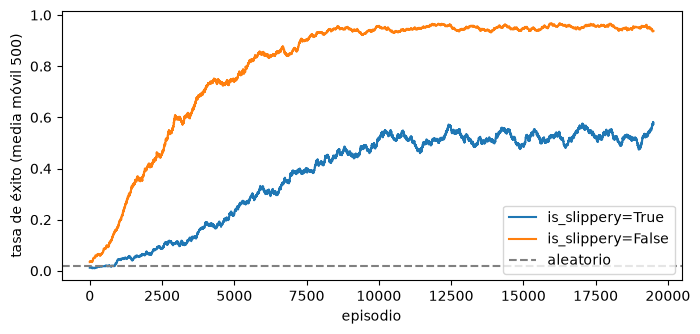

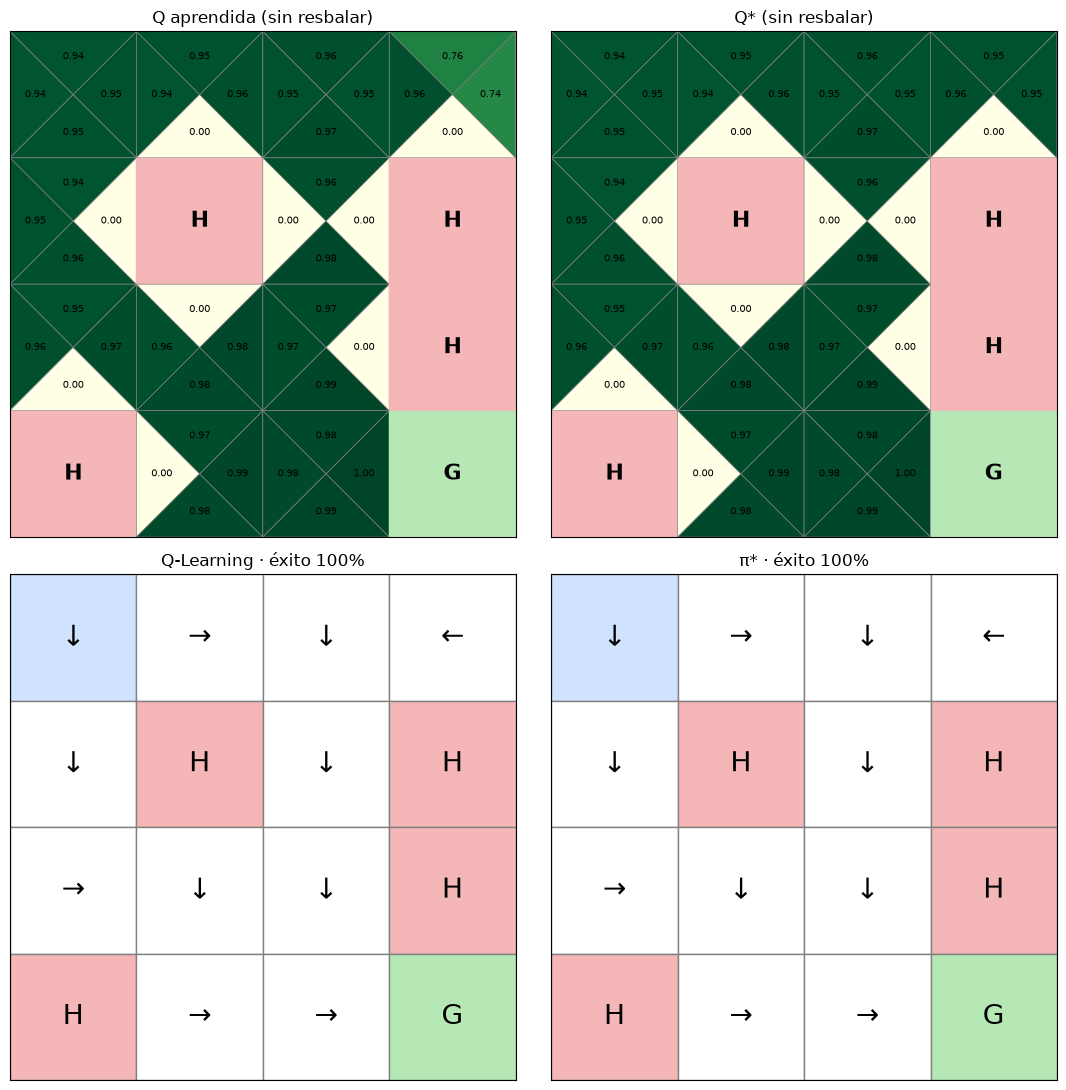

In [18]:
plt.figure(figsize=(8, 3.5))
plt.plot(media(ret_ql), label="is_slippery=True")
plt.plot(media(ret_det), label="is_slippery=False")
plt.axhline(ret_azar.mean(), color="gray", ls="--", label="aleatorio")
plt.xlabel("episodio"); plt.ylabel(f"tasa de éxito (media móvil {w})"); plt.legend(); plt.show()

vmax_det = Q_star_det[[s for s in range(nS) if s not in estados_terminales(env_det)]].max()
fig, ax = plt.subplots(2, 2, figsize=(11, 11))
graficar_Q(Q_det, env_det, "Q aprendida (sin resbalar)", ax[0, 0], vmax_det)
graficar_Q(Q_star_det, env_det, "Q* (sin resbalar)", ax[0, 1], vmax_det)
graficar_politica(pi_det, env_det, f"Q-Learning · éxito {simular_politica(env_det, pi_det, semilla=SEED):.0%}", ax[1, 0])
graficar_politica(pi_star_det, env_det, f"π* · éxito {simular_politica(env_det, pi_star_det, semilla=SEED):.0%}", ax[1, 1])
plt.tight_layout(); plt.show()

**Interpretación**: Ela ente llega al 100% de exito, igual que pi* y aprende unas 3 veces mas rapido. En train se queda en 95% por el 5% de exploracion.